# Section 2 Task 3 — Exploring Where SNNs May Have Advantages

## Part A · 数据集调研

1. **名称、来源和任务。** Spiking Heidelberg Digits（SHD）是 Zenke Lab 发布的公开语音脉冲数据集。任务是识别英语和德语的数字 0–9，共 20 类。[官方数据主页](https://zenkelab.org/resources/spiking-heidelberg-datasets-shd/)
2. **格式、规模和主要特征。** 12 位说话者共提供 10,420 条样本，其中官方训练集 8,156 条，测试集 2,264 条。人工耳蜗模型把每段语音转换为 700 个通道的事件。HDF5 文件保存各脉冲的时间（秒）、通道编号，以及样本的类别和说话者编号。[数据集论文](https://doi.org/10.1109/TNNLS.2020.3044364)
3. **时间信息和脉冲转换。** 每条样本已包含脉冲时间戳，可以直接按时间窗统计已有事件，无需再将语音编码为脉冲。
4. **为什么适合 SNN。** 不同发音会产生随时间变化的通道活动。SNN 可以用神经元状态累积先后到达的脉冲，利用活动出现的时刻和通道来识别发音。输入以事件形式到达，也适合支持事件驱动的硬件。

## Part B · 基础实验

### 1. SHD 脉冲可视化

从官方训练集中选取同一位说话者的英语 `seven` 和德语 `sieben`。图中一个点代表一个脉冲，横轴以每条样本的首个事件为零点，纵轴是原始耳蜗通道编号。

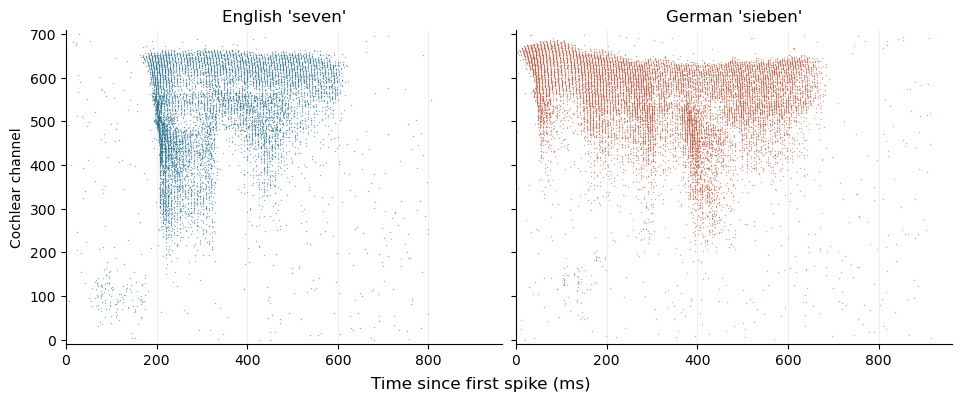

In [1]:
import json
import os
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

directory = Path.cwd()
repo = next(
    path
    for path in (directory, *directory.parents)
    if (path / "spike_encoding" / "prepare_shd.py").is_file()
)
out = Path(
    os.environ.get("SHD_TASK3_OUTPUT", repo.parent / "outputs" / "Section2_Task3_SHD")
).resolve()
data = out / "data"

fig, axes = plt.subplots(
    1, 2, figsize=(9.5, 3.9), sharex=True, sharey=True, layout="constrained"
)
with h5py.File(data / "shd_train.h5", "r") as train:
    labels = train["labels"][:]
    speakers = train["extra/speaker"][:]
    class_names = [key.decode("utf-8") for key in train["extra/keys"][:]]
    examples = [(7, "English", "#176485"), (17, "German", "#b84a2f")]
    for ax, (label, language, color) in zip(axes, examples, strict=True):
        index = int(np.flatnonzero((labels == label) & (speakers == 1))[0])
        times_s = train["spikes/times"][index]
        times_ms = (times_s - times_s[0]) * 1000
        units = train["spikes/units"][index]
        ax.scatter(times_ms, units, s=1, alpha=0.48, color=color, linewidths=0)
        ax.set_title(f"{language} '{class_names[label]}'")
        ax.set_ylim(-10, 710)
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

axes[0].set_xlim(left=0)
axes[0].set_ylabel("Cochlear channel")
fig.supxlabel("Time since first spike (ms)")
fig.savefig(out / "shd_event_rasters.png", dpi=180, bbox_inches="tight")
plt.show()

英语样本较密集的活动出现在约 200 ms，德语样本在更早的时间就出现密集发放。两条样本的活跃通道都随时间变化，说明脉冲图保留了发音过程的信息。

### 2. 使用 SpikCommander 分类

直接加载 SpikCommander 1L-8-128 的作者权重（seed 312）。将相邻 5 个耳蜗通道合并为 1 个，得到 140 个输入通道。模型将各时间步的类别概率求和，取分数最高的类别作为 Top-1 预测。[论文](https://arxiv.org/html/2511.07883) · [作者权重](https://github.com/JackieWang9811/SCommander/tree/a51266caba285d52cc022012dc7fb979a426f7eb/checkpoints/SHD)

**旧版事件分箱。** 每个窗口从第一条尚未分箱的脉冲开始，统计窗内各通道的脉冲，包含恰好落在窗末的事件。窗内静默占用该窗时长，贡献 0 个脉冲。窗口结束后，下一条事件再开启新窗，窗间静默不生成全零帧。例如同一通道在 0、3、8、25 ms 各有一个脉冲，10 ms 设置下，第一个窗口从 0 ms 开始，计数为 3，第二个窗口从 25 ms 开始，计数为 1。[SpikingJelly 历史分箱源码](https://github.com/fangwei123456/spikingjelly/blob/d0b7dd195cfdb672500f6b691bbbe70ce77cc5c9/spikingjelly/datasets/shd.py)

**GPU 复现设置。** 使用 SHD 官方测试集的 2,264 条样本。先按类别排序，同类样本按分箱文件名的字典序排列，批大小为 256。本次在 RTX 5090 上用 PyTorch 2.14.0+cu130 运行，cuDNN 卷积允许使用 TF32，矩阵乘法使用 FP32。按作者代码计算每批的 Top-1 准确率，再对 9 个批次取等权平均。[作者评估代码](https://github.com/JackieWang9811/SCommander/blob/a51266caba285d52cc022012dc7fb979a426f7eb/main_former_v2_shd_spikcommander.py#L125-L147)

在安装 CUDA 版 PyTorch、torchvision、NumPy、Matplotlib、h5py、SciPy、Seaborn 和 tqdm 的环境中，从仓库根目录运行以下命令。

```bash
python spike_encoding/prepare_shd.py
python spike_encoding/evaluate_spikcommander.py --device cuda
```

评估脚本下载并核验固定版本的作者源码与权重，在仓库同级的 `outputs/Section2_Task3_SHD` 写入 `spikcommander_paper_reproduction.json`。如果两个脚本使用了相同的 `--out`，运行 Notebook 时将 `SHD_TASK3_OUTPUT` 指向该目录。

### 3. 实验结果与分箱宽度的影响

分别使用 5、10 和 20 ms 的窗口进行事件分箱。三组均用同一份按 10 ms 配置训练的作者权重，保持测试样本、组批顺序和分类规则一致。表中同时列出每组预测正确的样本数与按作者口径计算的 Top-1。

In [2]:
from IPython.display import Markdown, display

result_path = out / "spikcommander_paper_reproduction.json"
result = (
    json.loads(result_path.read_text(encoding="utf-8")) if result_path.is_file() else {}
)
windows = result.get("window_results", [])
bin_widths = [row["input_bin_ms"] for row in windows]
if (
    result.get("binning") == "event-anchored"
    and result.get("device", "").split(":")[0] == "cuda"
    and bin_widths == [5, 10, 20]
):
    with h5py.File(data / "shd_test.h5", "r") as test:
        samples = len(test["labels"])
    assert all(row["samples"] == samples == 2264 for row in windows)

    rows = ["| 分箱宽度 | 正确数 / 总数 | Top-1（逐批平均） |", "|---:|---:|---:|"]
    for row in windows:
        rows.append(
            f"| {row['input_bin_ms']} ms | {row['correct']:,} / {row['samples']:,} | "
            f"{row['author_batch_average_accuracy']:.2%} |"
        )
    display(Markdown("\n".join(rows)))
else:
    print("运行上面的 CUDA 评估命令可生成 5、10、20 ms 的结果。")

| 分箱宽度 | 正确数 / 总数 | Top-1（逐批平均） |
|---:|---:|---:|
| 5 ms | 705 / 2,264 | 31.27% |
| 10 ms | 2,183 / 2,264 | 96.41% |
| 20 ms | 998 / 2,264 | 44.76% |

**10 ms 的 Top-1 为 96.41%**，与论文表 1 报告的分数一致。5 ms 把脉冲分到更多时间步，20 ms 则把更多脉冲合并到同一步。两种宽度都改变了模型收到的时间步数和每步的脉冲计数，在这份按 10 ms 训练的权重上准确率都低于 10 ms。[论文表 1](https://arxiv.org/html/2511.07883)